# Notebook 1: Data Ingestion, Cleaning, EDA & Feature Engineering

**Project:** Traders Behavior Analysis (`Traders-Behavior-Analysis`)  
**Scope:** Phases 1–4 of [`docs/PLAN.md`](docs/PLAN.md) — Data Audit, Cleaning & Alignment, Exploratory Data Analysis (EDA), and Feature Engineering.  
**Environment:** Local Jupyter Notebook (reproducible relative paths; no Colab dependencies).

---

## 0. Configuration, Reproducibility & Artifact Helpers

All processed CSVs are exported to `csv_files/` and all visual outputs (plots + tabular summary snapshots) are saved to `outputs/` at 300 DPI.

In [6]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Deterministic seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Resolve project directories robustly regardless of working directory
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "csv_files").exists() and (PROJECT_ROOT.parent / "csv_files").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

CSV_DIR = PROJECT_ROOT / "csv_files"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
CSV_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Consistent publication-quality visual styling
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "figure.figsize": (12, 6),
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": True,
})


def save_fig(fig: plt.Figure, filename: str, close: bool = False) -> Path:
    """Save a matplotlib figure cleanly to outputs/ at 300 DPI."""
    out_path = OUTPUT_DIR / filename
    fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"[Saved Image] {out_path.relative_to(PROJECT_ROOT)}")
    if close:
        plt.close(fig)
    return out_path


def save_table_image(
    df: pd.DataFrame,
    filename: str,
    title: str = "",
    max_rows: int = 25,
    col_width: float = 2.2,
    row_height: float = 0.45,
) -> Path:
    """Render a pandas DataFrame summary table as a crisp PNG image in outputs/."""
    view = df.head(max_rows).copy()
    n_rows, n_cols = view.shape
    fig_w = max(8, n_cols * col_width)
    fig_h = max(2.2, (n_rows + 1.8) * row_height)

    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=13, fontweight="bold", pad=12, loc="left")

    table = ax.table(
        cellText=view.astype(str).values,
        colLabels=[str(c) for c in view.columns],
        cellLoc="center",
        loc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(9.5)
    table.scale(1.0, 1.4)

    for (r, c), cell in table.get_celld().items():
        if r == 0:
            cell.set_facecolor("#1f3b5c")
            cell.set_text_props(color="white", weight="bold")
        else:
            cell.set_facecolor("#f7f9fc" if r % 2 == 0 else "white")
        cell.set_edgecolor("#d0d7de")

    return save_fig(fig, filename, close=True)


def export_csv(df: pd.DataFrame, filename: str, index: bool = False) -> Path:
    """Export a DataFrame to csv_files/ with row/column logging."""
    out_path = CSV_DIR / filename
    df.to_csv(out_path, index=index)
    print(f"[Saved CSV] {out_path.relative_to(PROJECT_ROOT)} | shape={df.shape}")
    return out_path


print(f"Project Root: {PROJECT_ROOT}")
print(f"CSV Directory: {CSV_DIR}")
print(f"Output Directory: {OUTPUT_DIR}")

Project Root: c:\Users\sgogo\OneDrive\Desktop\Portfolio Projects\TBD\Bitcoin-Sentiment\Traders-Behavior-Analysis
CSV Directory: c:\Users\sgogo\OneDrive\Desktop\Portfolio Projects\TBD\Bitcoin-Sentiment\Traders-Behavior-Analysis\csv_files
Output Directory: c:\Users\sgogo\OneDrive\Desktop\Portfolio Projects\TBD\Bitcoin-Sentiment\Traders-Behavior-Analysis\outputs


---
## 1. Phase 1: Data Acquisition & Initial Schema Inspection

- Copy raw CSVs from `dataset/` into `csv_files/` (non-destructive; preserves originals in `dataset/`).
- Inspect shapes, dtypes, memory footprint, date coverage, unique counts, and missingness.
- Note raw export characteristics (e.g., scientific-notation precision loss in `Timestamp` and `Trade ID`, IST timestamps in `Timestamp IST`).
- Export audit artifacts: `csv_files/00_data_audit_summary.csv`, `outputs/01_audit_schema_summary.png`, `outputs/01_audit_missingness.png`.

In [7]:
import shutil

DATASET_DIR = PROJECT_ROOT / "dataset"
RAW_FILES = ["fear_greed_index.csv", "historical_data.csv"]

for fname in RAW_FILES:
    src = DATASET_DIR / fname
    dst = CSV_DIR / fname
    if not dst.exists():
        if not src.exists():
            raise FileNotFoundError(f"Missing raw dataset file: {src}")
        shutil.copy2(src, dst)
        print(f"[Copied] {src.relative_to(PROJECT_ROOT)} -> {dst.relative_to(PROJECT_ROOT)}")
    else:
        print(f"[Exists] {dst.relative_to(PROJECT_ROOT)}")

available_csvs = sorted(CSV_DIR.glob("*.csv"))
print("Available CSV files in csv_files/:", [p.name for p in available_csvs])

[Copied] dataset\fear_greed_index.csv -> csv_files\fear_greed_index.csv
[Copied] dataset\historical_data.csv -> csv_files\historical_data.csv
Available CSV files in csv_files/: ['fear_greed_index.csv', 'historical_data.csv']


[Saved CSV] csv_files\00_data_audit_summary.csv | shape=(20, 8)


,Dataset,Rows,Cols,Memory_MB,Exact_Duplicates,Total_Missing_Cells,Date_Range_Raw
0,fear_greed_index.csv,"2,644",4,0.35,0,0,2018-02-01 -> 2025-05-02
1,historical_data.csv,"211,224",16,107.16,0,0,See Timestamp IST (DD-MM-YYYY HH:MM)


,dataset,column,dtype,non_null,null_count,null_pct,n_unique,sample_value
0,fear_greed_index,timestamp,int64,2644,0,0.0,2644,1517463000
1,fear_greed_index,value,int64,2644,0,0.0,90,30
2,fear_greed_index,classification,str,2644,0,0.0,5,Fear
3,fear_greed_index,date,str,2644,0,0.0,2644,2018-02-01
4,historical_data,Account,str,211224,0,0.0,32,0xae5eacaf9c6b9111fd53034a602c192a04e082ed
5,historical_data,Coin,str,211224,0,0.0,246,@107
6,historical_data,Execution Price,float64,211224,0,0.0,60162,7.9769
7,historical_data,Size Tokens,float64,211224,0,0.0,59304,986.87
8,historical_data,Size USD,float64,211224,0,0.0,118493,7872.16
9,historical_data,Side,str,211224,0,0.0,2,BUY


[Saved Image] outputs\01_audit_schema_summary.png
[Saved Image] outputs\01_audit_missingness.png


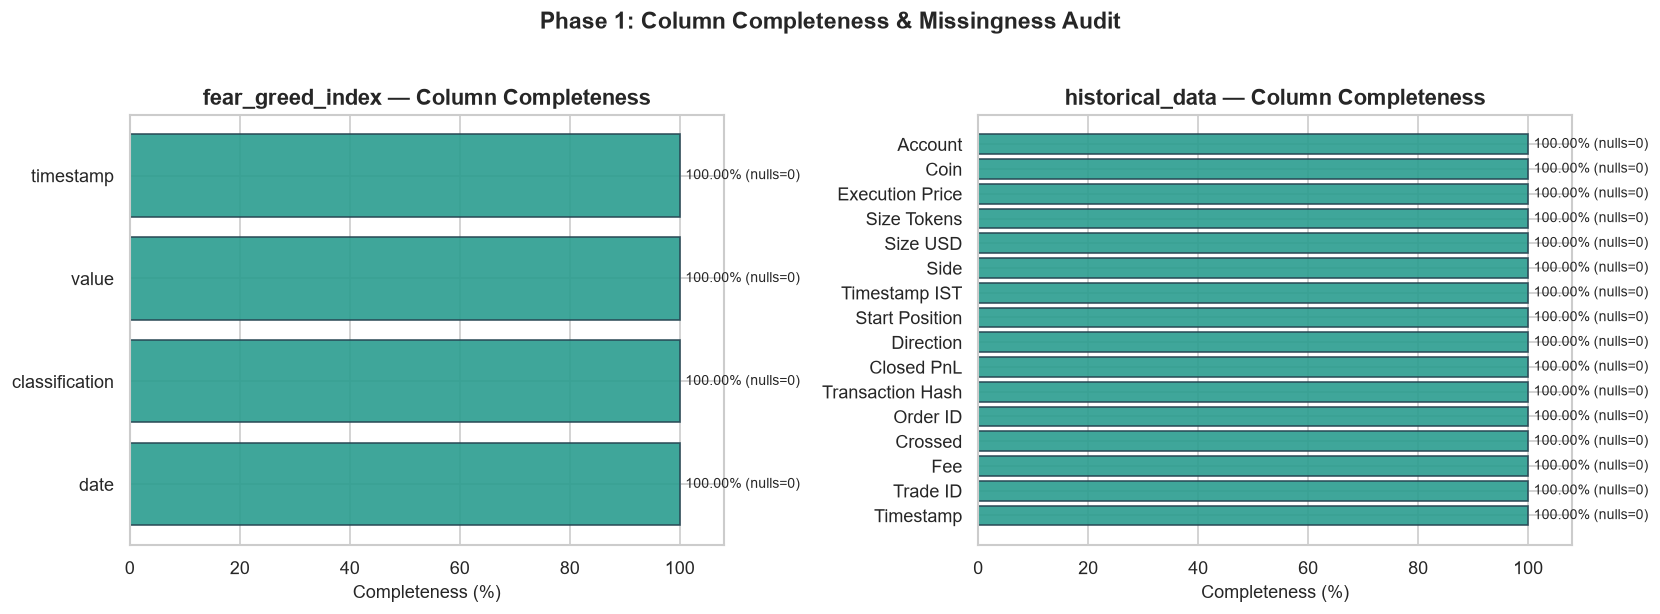

In [8]:
# Load raw datasets without altering values
raw_sentiment = pd.read_csv(CSV_DIR / "fear_greed_index.csv")
raw_trades = pd.read_csv(CSV_DIR / "historical_data.csv", low_memory=False)


def build_column_audit(df: pd.DataFrame, dataset_name: str) -> pd.DataFrame:
    """Build a per-column schema & missingness summary table."""
    records = []
    n_rows = len(df)
    for col in df.columns:
        s = df[col]
        n_null = int(s.isna().sum())
        records.append({
            "dataset": dataset_name,
            "column": col,
            "dtype": str(s.dtype),
            "non_null": int(s.notna().sum()),
            "null_count": n_null,
            "null_pct": round(100.0 * n_null / max(n_rows, 1), 4),
            "n_unique": int(s.nunique(dropna=True)),
            "sample_value": str(s.dropna().iloc[0]) if s.notna().any() else "NaN",
        })
    return pd.DataFrame(records)


audit_df = pd.concat([
    build_column_audit(raw_sentiment, "fear_greed_index"),
    build_column_audit(raw_trades, "historical_data"),
], ignore_index=True)

export_csv(audit_df, "00_data_audit_summary.csv")

# Dataset-level overview card
overview_df = pd.DataFrame([
    {
        "Dataset": "fear_greed_index.csv",
        "Rows": f"{len(raw_sentiment):,}",
        "Cols": raw_sentiment.shape[1],
        "Memory_MB": round(raw_sentiment.memory_usage(deep=True).sum() / 1e6, 2),
        "Exact_Duplicates": int(raw_sentiment.duplicated().sum()),
        "Total_Missing_Cells": int(raw_sentiment.isna().sum().sum()),
        "Date_Range_Raw": f"{raw_sentiment['date'].min()} -> {raw_sentiment['date'].max()}",
    },
    {
        "Dataset": "historical_data.csv",
        "Rows": f"{len(raw_trades):,}",
        "Cols": raw_trades.shape[1],
        "Memory_MB": round(raw_trades.memory_usage(deep=True).sum() / 1e6, 2),
        "Exact_Duplicates": int(raw_trades.duplicated().sum()),
        "Total_Missing_Cells": int(raw_trades.isna().sum().sum()),
        "Date_Range_Raw": "See Timestamp IST (DD-MM-YYYY HH:MM)",
    },
])

display(overview_df)
display(audit_df)

save_table_image(
    overview_df,
    "01_audit_schema_summary.png",
    title="Phase 1: Raw Dataset Schema & Integrity Overview",
    col_width=2.5,
)

# Missingness / Completeness Visual
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, sub) in zip(axes, audit_df.groupby("dataset", sort=False)):
    completeness = 100.0 - sub["null_pct"]
    colors = ["#2a9d8f" if v == 100.0 else "#e76f51" for v in completeness]
    ax.barh(sub["column"], completeness, color=colors, edgecolor="#264653", alpha=0.9)
    ax.set_xlim(0, 108)
    ax.set_xlabel("Completeness (%)")
    ax.set_title(f"{name} — Column Completeness")
    ax.invert_yaxis()
    for idx, (pct, n_null) in enumerate(zip(completeness, sub["null_count"])):
        ax.text(min(pct + 1, 101), idx, f"{pct:.2f}% (nulls={n_null})", va="center", fontsize=8.5)

fig.suptitle("Phase 1: Column Completeness & Missingness Audit", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
save_fig(fig, "01_audit_missingness.png")
plt.show()

---
## 2. Phase 2: Data Cleaning, Normalization & Temporal Alignment

### Key Cleaning Rules & Verification Steps
1. **Column Normalization:** Convert all headers to lowercase `snake_case`.
2. **Timestamp Parsing & Timezone Alignment:**
   - In `historical_data.csv`, the `Timestamp` column is stored in truncated scientific notation (e.g., `1.73E+12`), losing ~10 digits of precision. We **flag** it as `timestamp_raw_sci` and reconstruct exact timestamps from `Timestamp IST` (`%d-%m-%Y %H:%M`, localized to `Asia/Kolkata` and converted to `UTC`).
   - Extract both `trade_date_utc` and `trade_date_ist` so we can audit midnight-boundary differences and align with `fear_greed_index.csv` (`date`).
3. **Type Casting & Categorical Normalization:**
   - Coerce numeric columns safely (`execution_price`, `size_tokens`, `size_usd`, `start_position`, `closed_pnl`, `fee`, `value`) and inspect any parse failures.
   - Standardize `side`, `direction`, `crossed` (bool), and ordered `classification` (`Extreme Fear` < `Fear` < `Neutral` < `Greed` < `Extreme Greed`).
4. **Deduplication & Quality Flags (Non-Destructive):**
   - Remove only **exact full-row duplicates** (if any); preserve distinct partial fills that share an `order_id` or `transaction_hash`.
   - Add explicit diagnostic flags (`is_spot_index`, `is_closing_trade`, `is_maker`, `is_negative_fee`, `notional_mismatch_flag`, `extreme_size_flag`, `extreme_pnl_flag`) rather than silently dropping large whale trades.
5. **Temporal Merge & Exports:**
   - Left-join cleaned trades onto cleaned daily sentiment (plus 1-day lagged sentiment `sentiment_value_lag1`, `sentiment_class_lag1`) on `trade_date_utc`.
   - Verify zero row explosion, audit unmatched dates (if any), export `01_clean_sentiment.csv`, `01_clean_trader_data.csv`, `02_merged_trader_sentiment.csv`, `02_phase2_cleaning_summary.csv`, and save `outputs/01_audit_cleaning_funnel.png`, `outputs/01_audit_temporal_coverage.png`, `outputs/01_audit_phase2_summary_table.png`.

In [9]:
# 2.1 Clean & normalize market sentiment dataset
def to_snake_case(col: str) -> str:
    return (
        col.strip()
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
    )


SENTIMENT_ORDER = ["Extreme Fear", "Fear", "Neutral", "Greed", "Extreme Greed"]

clean_sent = raw_sentiment.copy()
clean_sent.columns = [to_snake_case(c) for c in clean_sent.columns]

n_sent_raw = len(clean_sent)
clean_sent["classification"] = clean_sent["classification"].astype(str).str.strip()
clean_sent["value"] = pd.to_numeric(clean_sent["value"], errors="coerce")
clean_sent["sentiment_date"] = pd.to_datetime(clean_sent["date"], format="%Y-%m-%d", errors="coerce")
clean_sent["timestamp_utc"] = pd.to_datetime(clean_sent["timestamp"], unit="s", utc=True, errors="coerce")

# Deduplicate on sentiment_date if needed
n_sent_date_dups = int(clean_sent["sentiment_date"].duplicated().sum())
clean_sent = (
    clean_sent.dropna(subset=["sentiment_date", "value", "classification"])
    .drop_duplicates(subset=["sentiment_date"], keep="last")
    .sort_values("sentiment_date")
    .reset_index(drop=True)
)

# Check calendar continuity (missing days in the sentiment series)
full_cal = pd.date_range(clean_sent["sentiment_date"].min(), clean_sent["sentiment_date"].max(), freq="D")
missing_sent_dates = sorted(set(full_cal) - set(clean_sent["sentiment_date"]))

# Coarse 3-bucket regime + ordered encoding + lagged sentiment
coarse_map = {
    "Extreme Fear": "Fear",
    "Fear": "Fear",
    "Neutral": "Neutral",
    "Greed": "Greed",
    "Extreme Greed": "Greed",
}
clean_sent["regime_coarse"] = clean_sent["classification"].map(coarse_map)
clean_sent["regime_score_ord"] = clean_sent["classification"].map(
    {k: i for i, k in enumerate(SENTIMENT_ORDER)}
)
clean_sent["sentiment_value_lag1"] = clean_sent["value"].shift(1)
clean_sent["sentiment_class_lag1"] = clean_sent["classification"].shift(1)
clean_sent["sentiment_delta_1d"] = clean_sent["value"].diff(1)
clean_sent["sentiment_date_str"] = clean_sent["sentiment_date"].dt.strftime("%Y-%m-%d")

print(f"Sentiment raw rows: {n_sent_raw:,} | Clean rows: {len(clean_sent):,} | Date duplicates: {n_sent_date_dups}")
print(f"Sentiment date range: {clean_sent['sentiment_date_str'].min()} -> {clean_sent['sentiment_date_str'].max()}")
print(f"Missing calendar days in sentiment index: {len(missing_sent_dates)}")
if missing_sent_dates:
    print("Sample missing sentiment dates:", [d.strftime("%Y-%m-%d") for d in missing_sent_dates[:10]])
print("Classification counts:\n", clean_sent["classification"].value_counts())

export_csv(clean_sent, "01_clean_sentiment.csv")

Sentiment raw rows: 2,644 | Clean rows: 2,644 | Date duplicates: 0
Sentiment date range: 2018-02-01 -> 2025-05-02
Missing calendar days in sentiment index: 4
Sample missing sentiment dates: ['2018-04-14', '2018-04-15', '2018-04-16', '2024-10-26']
Classification counts:
 classification
Fear             781
Greed            633
Extreme Fear     508
Neutral          396
Extreme Greed    326
Name: count, dtype: int64
[Saved CSV] csv_files\01_clean_sentiment.csv | shape=(2644, 12)


WindowsPath('c:/Users/sgogo/OneDrive/Desktop/Portfolio Projects/TBD/Bitcoin-Sentiment/Traders-Behavior-Analysis/csv_files/01_clean_sentiment.csv')

In [10]:
# 2.2 Clean & normalize historical trader dataset
clean_trades = raw_trades.copy()
clean_trades.columns = [to_snake_case(c) for c in clean_trades.columns]
clean_trades = clean_trades.rename(columns={"timestamp": "timestamp_raw_sci"})

n_trades_raw = len(clean_trades)

# Clean string identifiers & categoricals
for str_col in ["account", "coin", "side", "direction", "transaction_hash"]:
    clean_trades[str_col] = clean_trades[str_col].astype(str).str.strip()

clean_trades["side"] = clean_trades["side"].str.upper()

# Safe boolean parsing for 'crossed' (Taker = True, Maker = False)
clean_trades["crossed"] = (
    clean_trades["crossed"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map({"TRUE": True, "FALSE": False})
)

# Safe numeric casting
num_cols = ["execution_price", "size_tokens", "size_usd", "start_position", "closed_pnl", "fee"]
coerce_failures = {}
for col in num_cols:
    before_na = int(clean_trades[col].isna().sum())
    clean_trades[col] = pd.to_numeric(clean_trades[col], errors="coerce")
    after_na = int(clean_trades[col].isna().sum())
    coerce_failures[col] = after_na - before_na

print("Numeric coercion failures:", coerce_failures)

# Parse Timestamp IST (%d-%m-%Y %H:%M) -> localized IST -> UTC
dt_ist_naive = pd.to_datetime(clean_trades["timestamp_ist"], format="%d-%m-%Y %H:%M", errors="coerce")
# Fallback for any rows that might include seconds
mask_unparsed = dt_ist_naive.isna() & clean_trades["timestamp_ist"].notna()
if mask_unparsed.any():
    dt_ist_naive.loc[mask_unparsed] = pd.to_datetime(
        clean_trades.loc[mask_unparsed, "timestamp_ist"], dayfirst=True, errors="coerce"
    )

n_ts_failed = int(dt_ist_naive.isna().sum())
print(f"Timestamp IST parse failures: {n_ts_failed}")

dt_ist = dt_ist_naive.dt.tz_localize("Asia/Kolkata", ambiguous="infer", nonexistent="shift_forward")
dt_utc = dt_ist.dt.tz_convert("UTC")

clean_trades["timestamp_ist_dt"] = dt_ist_naive
clean_trades["timestamp_utc"] = dt_utc
clean_trades["trade_date_utc"] = dt_utc.dt.strftime("%Y-%m-%d")
clean_trades["trade_date_ist"] = dt_ist_naive.dt.strftime("%Y-%m-%d")
clean_trades["hour_utc"] = dt_utc.dt.hour
clean_trades["day_of_week_utc"] = dt_utc.dt.day_name()

# Exact full-row duplicates check (before dropping)
n_exact_dups = int(clean_trades.duplicated().sum())
clean_trades = clean_trades.drop_duplicates().reset_index(drop=True)

# Drop rows missing critical timestamp or execution fields (if any)
n_before_critical_drop = len(clean_trades)
clean_trades = clean_trades.dropna(subset=["timestamp_utc", "execution_price", "size_tokens", "size_usd"]).reset_index(drop=True)
n_dropped_critical = n_before_critical_drop - len(clean_trades)

# Non-destructive diagnostic & domain flags
clean_trades["is_spot_index"] = clean_trades["coin"].str.startswith("@")
clean_trades["is_maker"] = ~clean_trades["crossed"].fillna(False)
clean_trades["is_closing_trade"] = clean_trades["closed_pnl"] != 0
clean_trades["is_negative_fee"] = clean_trades["fee"] < 0
clean_trades["computed_notional_usd"] = clean_trades["execution_price"] * clean_trades["size_tokens"]
clean_trades["notional_abs_diff"] = (clean_trades["size_usd"] - clean_trades["computed_notional_usd"]).abs()
clean_trades["notional_mismatch_flag"] = clean_trades["notional_abs_diff"] > np.maximum(1.0, 0.01 * clean_trades["size_usd"])

size_p999 = clean_trades["size_usd"].quantile(0.999)
pnl_abs_p999 = clean_trades["closed_pnl"].abs().quantile(0.999)
clean_trades["extreme_size_flag"] = clean_trades["size_usd"] > size_p999
clean_trades["extreme_pnl_flag"] = clean_trades["closed_pnl"].abs() > pnl_abs_p999
clean_trades["date_shifted_ist_to_utc"] = clean_trades["trade_date_ist"] != clean_trades["trade_date_utc"]

print(f"Trader raw rows: {n_trades_raw:,} | Exact dups removed: {n_exact_dups:,} | Critical NaNs dropped: {n_dropped_critical:,} | Clean rows: {len(clean_trades):,}")
print(f"UTC date range: {clean_trades['trade_date_utc'].min()} -> {clean_trades['trade_date_utc'].max()}")
print(f"Unique accounts: {clean_trades['account'].nunique():,} | Unique coins: {clean_trades['coin'].nunique():,}")
print(f"Trades shifting calendar day IST -> UTC: {int(clean_trades['date_shifted_ist_to_utc'].sum()):,} ({100*clean_trades['date_shifted_ist_to_utc'].mean():.2f}%)")
print(f"Notional mismatch flags (>max($1, 1%)): {int(clean_trades['notional_mismatch_flag'].sum()):,}")
print("Direction value counts:\n", clean_trades["direction"].value_counts())

export_csv(clean_trades, "01_clean_trader_data.csv")

Numeric coercion failures: {'execution_price': 0, 'size_tokens': 0, 'size_usd': 0, 'start_position': 0, 'closed_pnl': 0, 'fee': 0}
Timestamp IST parse failures: 0
Trader raw rows: 211,224 | Exact dups removed: 0 | Critical NaNs dropped: 0 | Clean rows: 211,224
UTC date range: 2023-04-30 -> 2025-05-01
Unique accounts: 32 | Unique coins: 246
Trades shifting calendar day IST -> UTC: 53,322 (25.24%)
Notional mismatch flags (>max($1, 1%)): 0
Direction value counts:
 direction
Open Long                    49895
Close Long                   48678
Open Short                   39741
Close Short                  36013
Sell                         19902
Buy                          16716
Spot Dust Conversion           142
Short > Long                    70
Long > Short                    57
Auto-Deleveraging                8
Liquidated Isolated Short        1
Settlement                       1
Name: count, dtype: int64
[Saved CSV] csv_files\01_clean_trader_data.csv | shape=(211224, 32)


WindowsPath('c:/Users/sgogo/OneDrive/Desktop/Portfolio Projects/TBD/Bitcoin-Sentiment/Traders-Behavior-Analysis/csv_files/01_clean_trader_data.csv')

In [11]:
# 2.3 Temporal alignment & merge with market sentiment
sent_merge_cols = [
    "sentiment_date_str",
    "value",
    "classification",
    "regime_coarse",
    "regime_score_ord",
    "sentiment_value_lag1",
    "sentiment_class_lag1",
    "sentiment_delta_1d",
]

merged_df = clean_trades.merge(
    clean_sent[sent_merge_cols].rename(columns={
        "sentiment_date_str": "trade_date_utc",
        "value": "sentiment_value",
        "classification": "sentiment_class",
    }),
    on="trade_date_utc",
    how="left",
    validate="many_to_one",
)

# Assert row count preservation
assert len(merged_df) == len(clean_trades), (
    f"Row count changed on merge: {len(clean_trades)} -> {len(merged_df)}"
)

n_unmatched_utc = int(merged_df["sentiment_class"].isna().sum())
unmatched_dates_utc = sorted(merged_df.loc[merged_df["sentiment_class"].isna(), "trade_date_utc"].unique())

# Compare overlap if joined on IST date instead (diagnostic only)
ist_matched = clean_trades["trade_date_ist"].isin(set(clean_sent["sentiment_date_str"]))
n_unmatched_ist = int((~ist_matched).sum())

print(f"Merged shape: {merged_df.shape}")
print(f"Matched on UTC date: {len(merged_df) - n_unmatched_utc:,} / {len(merged_df):,} (Unmatched: {n_unmatched_utc:,})")
if unmatched_dates_utc:
    print("Unmatched UTC dates:", unmatched_dates_utc)
print(f"Diagnostic — Unmatched if joined on IST date: {n_unmatched_ist:,}")

export_csv(merged_df, "02_merged_trader_sentiment.csv")

Merged shape: (211224, 39)
Matched on UTC date: 211,224 / 211,224 (Unmatched: 0)
Diagnostic — Unmatched if joined on IST date: 6
[Saved CSV] csv_files\02_merged_trader_sentiment.csv | shape=(211224, 39)


WindowsPath('c:/Users/sgogo/OneDrive/Desktop/Portfolio Projects/TBD/Bitcoin-Sentiment/Traders-Behavior-Analysis/csv_files/02_merged_trader_sentiment.csv')

,Metric,Value
0,Raw Sentiment Rows,"2,644"
1,Clean Sentiment Rows,"2,644"
2,Missing Sentiment Calendar Days,4
3,Sentiment Date Window,2018-02-01 to 2025-05-02
4,Raw Trader Rows,"211,224"
5,Exact Duplicate Trader Rows Removed,0
6,Critical Null Rows Dropped,0
7,Clean & Merged Trader Rows,"211,224"
8,Trader UTC Date Window,2023-04-30 to 2025-05-01
9,Unique Accounts / Unique Coins,32 / 246


[Saved CSV] csv_files\02_phase2_cleaning_summary.csv | shape=(14, 2)
[Saved Image] outputs\01_audit_phase2_summary_table.png
[Saved Image] outputs\01_audit_cleaning_funnel.png


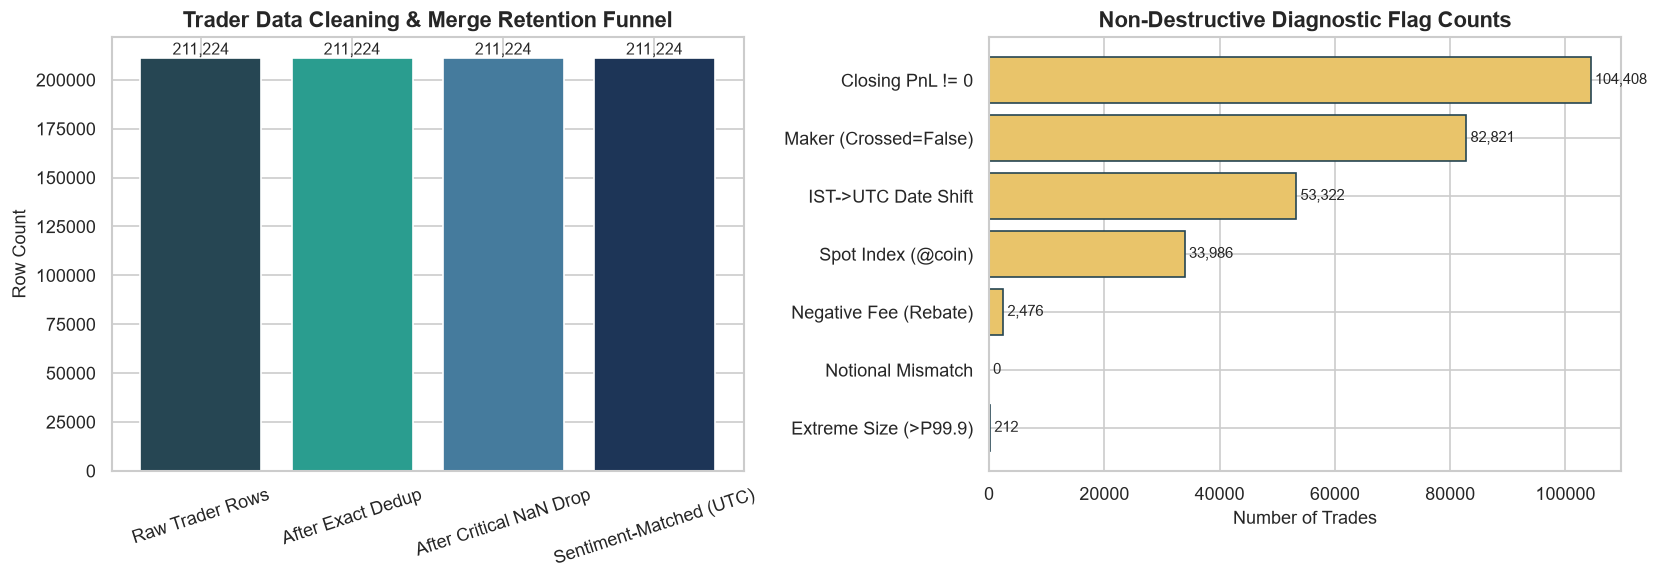

[Saved Image] outputs\01_audit_temporal_coverage.png


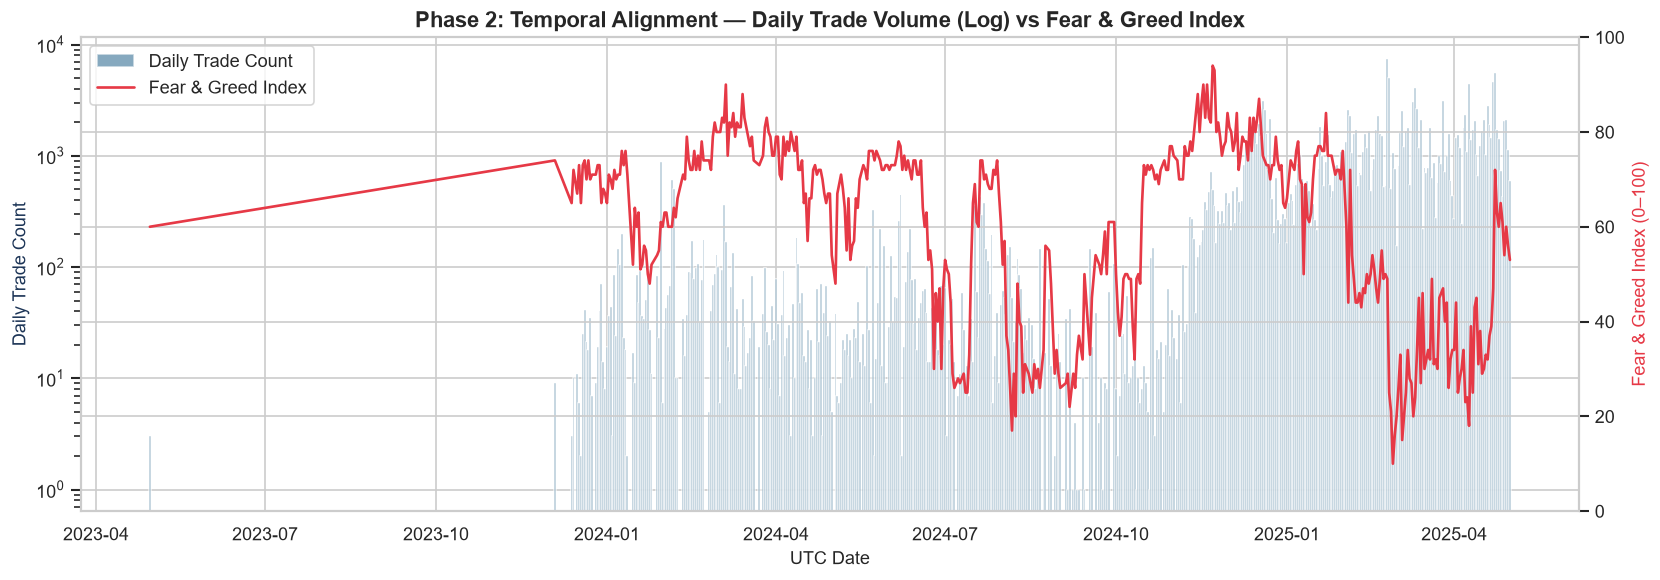

In [12]:
# 2.4 Phase 2 Summary Table & Audit Visuals
phase2_summary = pd.DataFrame([
    {"Metric": "Raw Sentiment Rows", "Value": f"{n_sent_raw:,}"},
    {"Metric": "Clean Sentiment Rows", "Value": f"{len(clean_sent):,}"},
    {"Metric": "Missing Sentiment Calendar Days", "Value": f"{len(missing_sent_dates):,}"},
    {"Metric": "Sentiment Date Window", "Value": f"{clean_sent['sentiment_date_str'].min()} to {clean_sent['sentiment_date_str'].max()}"},
    {"Metric": "Raw Trader Rows", "Value": f"{n_trades_raw:,}"},
    {"Metric": "Exact Duplicate Trader Rows Removed", "Value": f"{n_exact_dups:,}"},
    {"Metric": "Critical Null Rows Dropped", "Value": f"{n_dropped_critical:,}"},
    {"Metric": "Clean & Merged Trader Rows", "Value": f"{len(merged_df):,}"},
    {"Metric": "Trader UTC Date Window", "Value": f"{merged_df['trade_date_utc'].min()} to {merged_df['trade_date_utc'].max()}"},
    {"Metric": "Unique Accounts / Unique Coins", "Value": f"{merged_df['account'].nunique():,} / {merged_df['coin'].nunique():,}"},
    {"Metric": "Trades Matched to Sentiment (UTC)", "Value": f"{len(merged_df) - n_unmatched_utc:,} ({100*(len(merged_df)-n_unmatched_utc)/len(merged_df):.2f}%)"},
    {"Metric": "Trades Shifting Date IST -> UTC", "Value": f"{int(merged_df['date_shifted_ist_to_utc'].sum()):,} ({100*merged_df['date_shifted_ist_to_utc'].mean():.2f}%)"},
    {"Metric": "Spot Index Trades (@coin)", "Value": f"{int(merged_df['is_spot_index'].sum()):,} ({100*merged_df['is_spot_index'].mean():.2f}%)"},
    {"Metric": "Closing / Realized-PnL Trades", "Value": f"{int(merged_df['is_closing_trade'].sum()):,} ({100*merged_df['is_closing_trade'].mean():.2f}%)"},
])

display(phase2_summary)
export_csv(phase2_summary, "02_phase2_cleaning_summary.csv")
save_table_image(
    phase2_summary,
    "01_audit_phase2_summary_table.png",
    title="Phase 2: Cleaning, Alignment & Merge Audit Summary",
    col_width=4.5,
)

# Figure A: Cleaning Funnel & Diagnostic Flags
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

funnel_labels = [
    "Raw Trader Rows",
    "After Exact Dedup",
    "After Critical NaN Drop",
    "Sentiment-Matched (UTC)",
]
funnel_vals = [
    n_trades_raw,
    n_trades_raw - n_exact_dups,
    len(clean_trades),
    len(merged_df) - n_unmatched_utc,
]
bars = axes[0].bar(funnel_labels, funnel_vals, color=["#264653", "#2a9d8f", "#457b9d", "#1d3557"])
axes[0].set_title("Trader Data Cleaning & Merge Retention Funnel")
axes[0].set_ylabel("Row Count")
axes[0].tick_params(axis="x", rotation=18)
for bar, val in zip(bars, funnel_vals):
    axes[0].text(bar.get_x() + bar.get_width() / 2, val, f"{val:,}", ha="center", va="bottom", fontsize=9.5)

flag_counts = {
    "Closing PnL != 0": int(merged_df["is_closing_trade"].sum()),
    "Maker (Crossed=False)": int(merged_df["is_maker"].sum()),
    "IST->UTC Date Shift": int(merged_df["date_shifted_ist_to_utc"].sum()),
    "Spot Index (@coin)": int(merged_df["is_spot_index"].sum()),
    "Negative Fee (Rebate)": int(merged_df["is_negative_fee"].sum()),
    "Notional Mismatch": int(merged_df["notional_mismatch_flag"].sum()),
    "Extreme Size (>P99.9)": int(merged_df["extreme_size_flag"].sum()),
}
axes[1].barh(list(flag_counts.keys()), list(flag_counts.values()), color="#e9c46a", edgecolor="#264653")
axes[1].invert_yaxis()
axes[1].set_title("Non-Destructive Diagnostic Flag Counts")
axes[1].set_xlabel("Number of Trades")
for idx, val in enumerate(flag_counts.values()):
    axes[1].text(val, idx, f" {val:,}", va="center", fontsize=9)

plt.tight_layout()
save_fig(fig, "01_audit_cleaning_funnel.png")
plt.show()

# Figure B: Temporal Coverage — Daily Trade Volume vs Sentiment Overlay
daily_cov = (
    merged_df.groupby("trade_date_utc", as_index=False)
    .agg(
        trade_count=("account", "size"),
        notional_usd=("size_usd", "sum"),
        sentiment_value=("sentiment_value", "first"),
    )
)
daily_cov["trade_date_dt"] = pd.to_datetime(daily_cov["trade_date_utc"])
daily_cov = daily_cov.sort_values("trade_date_dt")

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(daily_cov["trade_date_dt"], daily_cov["trade_count"], color="#457b9d", alpha=0.65, width=1.0, label="Daily Trade Count")
ax1.set_ylabel("Daily Trade Count", color="#1d3557")
ax1.set_xlabel("UTC Date")
ax1.set_yscale("log")

ax2 = ax1.twinx()
ax2.plot(daily_cov["trade_date_dt"], daily_cov["sentiment_value"], color="#e63946", linewidth=1.6, label="Fear & Greed Index")
ax2.set_ylabel("Fear & Greed Index (0–100)", color="#e63946")
ax2.set_ylim(0, 100)

ax1.set_title("Phase 2: Temporal Alignment — Daily Trade Volume (Log) vs Fear & Greed Index")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
plt.tight_layout()
save_fig(fig, "01_audit_temporal_coverage.png")
plt.show()

---
## 3. Phase 3: Exploratory Data Analysis (EDA) & Visual Logging

1. **3A. Market Sentiment / Risk Regimes:** Regime frequency, timeline, transition matrix (`outputs/02_eda_sentiment_*.png`).
2. **3B. Trader Activity, Volume & Profitability:** Global KPIs table image, PnL & volume distributions, leverage & side breakdown, symbol breakdown, trader concentration (`outputs/03_eda_*.png`).
3. **3C. Behavior Across Regimes:** Activity, PnL, risk-taking, and temporal heatmaps conditioned on sentiment regime (`outputs/04_eda_*.png`).
4. **3D. Correlations & Lead-Lag Analysis:** Spearman/Pearson heatmaps and lagged behavior relationships (`outputs/05_eda_*.png`).

In [ ]:
# TODO: Implement Phase 3 EDA visualizations and save outputs/*.png

---
## 4. Phase 4: Feature Engineering & Behavioral/Risk Metrics

- Engineer trade-level enriched metrics (`notional_usd`, `return_on_notional`, `risk_adjusted_pnl`, regime streak & lagged features).
- Build daily aggregated dataset -> `csv_files/03_features_daily_regime.csv`.
- Build trader-level behavioral profile dataset -> `csv_files/04_features_trader_profiles.csv`.
- Save feature distributions and summary table images (`outputs/06_features_*.png`).

In [ ]:
# TODO: Implement Phase 4 feature engineering and export processed feature CSVs